## **Messwerte**

In [5]:
import numpy as np
import uncertainties as uc
import uncertainties.unumpy as unp


f_data = np.array([0.1, 0.25, 0.5, 0.75, 1, 2.5, 5, 7.5, 9, 9.25, 9.5, 9.75, 10, 10.25, 10.5, 10.75, 11, 25, 50, 75, 100]) *10**3 #gemessene Frequenzen in Hz
f_fehler = 0.1
f = unp.uarray(f_data, f_fehler)
omega = f * 2* np.pi

"""-----------------------------------------------------------------------------------------------------------------------------------------------------------"""

U_in_data = np.array([21, 20, 19, 18, 17, 16, 15, 14, 13, 12, 11, 10, 9, 8, 7, 6, 5, 4, 3, 2, 1]) #Eingangsspannung in V
U_in_fehler = 0.1
U_in = unp.uarray(U_in_data, U_in_fehler)

"""-----------------------------------------------------------------------------------------------------------------------------------------------------------"""

U_out_data = np.array([1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21]) #Ausgangsspannung in V
U_out_fehler = 0.1
U_out = unp.uarray(U_out_data, U_out_fehler)

"""-----------------------------------------------------------------------------------------------------------------------------------------------------------"""

deltaT_data = np.array([0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0, 1.1, 1.2, 1.3, 1.4, 1.5, 1.6, 1.7, 1.8, 1.9, 2.0, 2.1]) #Zeitliche Verschiebung der Spannungen in s
deltaT_fehler = 0.1
deltaT = unp.uarray(deltaT_data, deltaT_fehler)

"""-----------------------------------------------------------------------------------------------------------------------------------------------------------"""

deltaPhi = omega * deltaT #Phasenverschiebung in rad


## **Bodeplots**

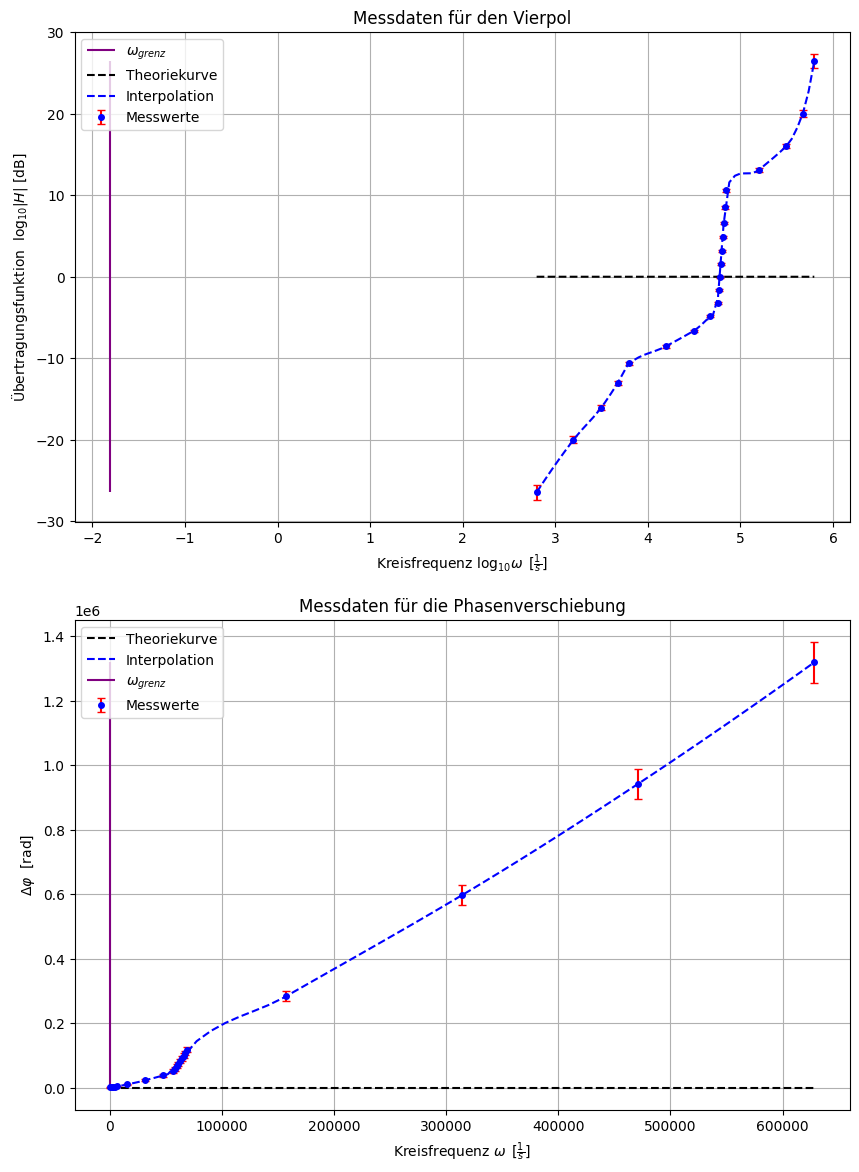

In [6]:
import scipy
import matplotlib.pyplot as plt

#Übergangsfunktion

H = U_out / U_in

H_dB = 20* unp.log10(H)

omega_log = unp.log10(omega)

fig, (ax1, ax2) = plt.subplots(2,1, figsize = (10,14))

%store -r R
%store -r C
# noinspection PyUnresolvedReferences
omega_grenz = 1/(R*C)

ax1.errorbar(unp.nominal_values(omega_log), unp.nominal_values(H_dB), yerr= unp.std_devs(H_dB), fmt="o", label="Messwerte", color="blue", markersize=4, capsize=3, ecolor="r")

ax1.vlines(np.log10(unp.nominal_values(omega_grenz)), ymin = np.min(unp.nominal_values(H_dB)), ymax = np.max(unp.nominal_values(H_dB)), color = "purple", label = "$\\omega _{grenz}$")

xwerte = np.linspace(np.min(unp.nominal_values(omega_log)), np.max(unp.nominal_values(omega_log)))

# noinspection PyUnresolvedReferences
ax1.plot(xwerte, 1/np.sqrt(1 + (xwerte*unp.nominal_values(R)*unp.nominal_values(C))**2) , label = "Theoriekurve", color = "black", linestyle = "--")

fit = scipy.interpolate.Akima1DInterpolator(unp.nominal_values(omega_log), unp.nominal_values(H_dB))

ax1.plot(xwerte, fit(xwerte) , label = "Interpolation", color = "blue", linestyle = "--")


#TODO: Flankensteilheit in dB/dec

ax1.set_xlabel("Kreisfrequenz $ \\mathrm{log} _{10} \\omega \\,$ $[\\frac{1}{s}]$")
ax1.set_ylabel("Übertragungsfunktion  $ \\mathrm{log} _{10} |H|$ [dB]")
ax1.grid(True)
ax1.set_title("Messdaten für den Vierpol")
ax1.legend()

"""-----------------------------------------------------------------------------------------------------------------------------------------------------------"""
#Phasenverschiebung

ax2.errorbar(unp.nominal_values(omega), unp.nominal_values(deltaPhi), yerr= unp.std_devs(deltaPhi), fmt="o", label="Messwerte", color="blue", markersize=4, capsize=3, ecolor="r")

xwerte = np.linspace(np.min(unp.nominal_values(omega)), np.max(unp.nominal_values(omega)))
# noinspection PyUnresolvedReferences
Theoriekurve = unp.arctan(xwerte*R*C)

ax2.plot(xwerte, unp.nominal_values(Theoriekurve) , label = "Theoriekurve", color = "black", linestyle = "--")

fit = scipy.interpolate.Akima1DInterpolator(unp.nominal_values(omega), unp.nominal_values(deltaPhi))

ax2.plot(xwerte, fit(xwerte) , label = "Interpolation", color = "blue", linestyle = "--")

ax2.vlines(unp.nominal_values(omega_grenz), ymin = np.min(unp.nominal_values(deltaPhi)), ymax = np.max(unp.nominal_values(deltaPhi)), color = "purple", label = "$\\omega _{grenz}$")


#ax2.yaxis.set_minor_locator(plt.MultipleLocator(3.14/2))
#ax2.yaxis.set_major_locator(plt.MultipleLocator(3.14))
ax2.set_xlabel("Kreisfrequenz $\\omega \\,$ $[\\frac{1}{s}]$")
ax2.set_ylabel("$\\Delta \\varphi$  $[\\mathrm{rad}]$")
ax2.grid(True)
ax2.set_title("Messdaten für die Phasenverschiebung")
ax2.legend()
